<a href="https://colab.research.google.com/github/jakubs692/University/blob/main/DNN/dnn01-EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><img src='https://drive.google.com/uc?id=1_utx_ZGclmCwNttSe40kYA6VHzNocdET' height="60"></center>

AI TECH - Akademia Innowacyjnych Zastosowań Technologii Cyfrowych. Program Operacyjny Polska Cyfrowa na lata 2014-2020
<hr>

<center><img src='https://drive.google.com/uc?id=1BXZ0u3562N_MqCLcekI-Ens77Kk4LpPm'></center>

<center>
Projekt współfinansowany ze środków Unii Europejskiej w ramach Europejskiego Funduszu Rozwoju Regionalnego
Program Operacyjny Polska Cyfrowa na lata 2014-2020,
Oś Priorytetowa nr 3 "Cyfrowe kompetencje społeczeństwa" Działanie  nr 3.2 "Innowacyjne rozwiązania na rzecz aktywizacji cyfrowej"
Tytuł projektu:  „Akademia Innowacyjnych Zastosowań Technologii Cyfrowych (AI Tech)”
    </center>

# Lab 1: Data analysis
In this lab, you will build a machine learning model to predict prices of flats (apartments).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Dataset

Each row represents a property listing. Our goal is to train a model that predicts a property's target `price` (the last column) based on its input features (the remaining columns).

Use the train file for all data analysis, cleaning, feature engineering, and model training. All preprocessing decisions must be derived **only** from this dataset.<br>
The test file represents unseen data, it must be used exclusively for evaluating the final model's performance. Knowing it makes prediction trivial. Even small decisions based on it would constitute data leakage.

In [2]:
!wget --no-verbose -O lab1_apartments_train.csv https://mimuw.edu.pl/~mwrochna/upload/lab1_apartments_train.csv
!wget --no-verbose -O lab1_apartments_test.csv https://mimuw.edu.pl/~mwrochna/upload/lab1_apartments_test.csv
!head lab1_apartments_train.csv lab1_apartments_test.csv

2026-10-15 18:53:48 URL:https://mimuw.edu.pl/~mwrochna/upload/lab1_apartments_train.csv [8292/8292] -> "lab1_apartments_train.csv" [1]
2026-10-15 18:53:49 URL:https://mimuw.edu.pl/~mwrochna/upload/lab1_apartments_test.csv [6814/6814] -> "lab1_apartments_test.csv" [1]
==> lab1_apartments_train.csv <==
area,district,bedrooms,bathrooms,build_year,parking,price
104.0,mokotowo,2.0,2,1940,1,780094.0
43.0,ochotowo,1.0,1,1970,1,346912.0
128.0,grodziskowo,3.0,2,1916,1,523466.0
112.0,mokotowo,3.0,2,1920,1,830965.0
149.0,mokotowo,3.0,3,1977,0,1090479.0
80.0,ochotowo,2.0,2,1937,0,599060.0
58.0,ochotowo,2.0,1,1922,0,463639.0
23.0,ochotowo,1.0,1,1929,0,166785.0
40.0,mokotowo,1.0,1,1973,0,318849.0

==> lab1_apartments_test.csv <==
area,district,bedrooms,bathrooms,build_year,parking,price
71,wolowo,2,2,1912,1,322227.0
45,mokotowo,1,1,1938,0,295878.0
38,mokotowo,1,1,1999,1,306530.0
70,ochotowo,2,2,1980,1,553641.0
136,mokotowo,3,2,1939,1,985348.0
128,wolowo,3,2,1983,1,695726.0
23,grodziskowo,1,1,1975,0,

In [3]:
train_df = pd.read_csv("lab1_apartments_train.csv")
test_df = pd.read_csv("lab1_apartments_test.csv")

train_df

,area,district,bedrooms,bathrooms,build_year,parking,price
0,104.0,mokotowo,2.0,2,1940,1,7.800940e+05
1,43.0,ochotowo,1.0,1,1970,1,3.469120e+05
2,128.0,grodziskowo,3.0,2,1916,1,5.234660e+05
3,112.0,mokotowo,3.0,2,1920,1,8.309650e+05
4,149.0,mokotowo,3.0,3,1977,0,1.090479e+06
...,...,...,...,...,...,...,...
217,80.0,ochootowo,2.0,2,1937,0,5.990600e+05
218,72.0,grodziskowo,3.0,1,2034,1,3.907637e+05
219,84.0,ochotowo,2.0,1,2031,0,5.679256e+05
220,0.0,grodziskowo,1.0,1,2004,1,4.496779e+05


## Exploratory Data Analysis (EDA)

Your first goal is to get your hands dirty with `train_df` — raw datasets are rarely clean. Your model's performance depends on how well you understand and validate the data.

Use [Pandas](https://pandas.pydata.org/docs/reference/frame.html), [Matplotlib](https://matplotlib.org/stable/plot_types/index.html), or [Seaborn](https://seaborn.pydata.org/tutorial/introduction.html) to find issues in the dataset.
Take time to write your own exploration code and document what anomalies you spot.
You will need to address them in the next step!

<details markdown="1">
<summary>Hints</summary>

* [pd.DataFrame.describe()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)
* [isna()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html)
* [value_counts()](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
* [duplicated()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html)
* [hist()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html) or [plt.hist()](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)
* [seaborn.pairplot()](https://seaborn.pydata.org/generated/seaborn.pairplot.html) or [plt.scatter()](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)

</details>

In [4]:
### TODO ###

print(train_df.describe())
print(train_df.value_counts())

nulls = train_df[train_df.isnull().any(axis=1)]
nonpositive = train_df[train_df.select_dtypes(include=[np.number]) <= 0].count()

print("nulls:\n", nulls, "\n")
print("non-positive:\n", nonpositive, "\n")
print("duplicates:\n", train_df[train_df.duplicated(keep=False)], "\n")


df = train_df[(train_df["price"] > 0) & (train_df["area"] > 0)]
df.dropna()
df = df.drop_duplicates()

             area    bedrooms   bathrooms   build_year     parking  \
count  220.000000  220.000000  222.000000   222.000000  222.000000   
mean    81.522727    2.445455    1.648649  1963.445946    0.513514   
std     39.292422    6.650555    0.667929    31.070847    0.500947   
min      0.000000    1.000000    1.000000  1912.000000    0.000000   
25%     50.000000    1.000000    1.000000  1937.000000    0.000000   
50%     77.000000    2.000000    2.000000  1962.000000    1.000000   
75%    111.250000    3.000000    2.000000  1992.000000    1.000000   
max    205.000000  100.000000    5.000000  2034.000000    1.000000   

              price  
count  2.220000e+02  
mean   5.219942e+05  
std    3.606854e+05  
min   -6.745005e+04  
25%    3.046940e+05  
50%    4.702745e+05  
75%    6.682392e+05  
max    3.894993e+06  
area   district     bedrooms  bathrooms  build_year  parking  price       
143.0  grodziskowo  3.0       3          2010        0        5.509030e+05    3
20.0   wolowo   

## Data cleaning

Discuss how each issue can be addressed.

As a shortcut, here we can drop the last few rows to make the dataset clean.
In reality you would use `df.dropna()`, `fillna()`, `drop_duplicates()`, `groupby().mean()`, `clamp()`, filters like `df = df[df["price"] > 0]`,and more complex operations.

Note that in a cleaning pipeline:
* row filtering and target sanitization (e.g., dropping negative prices, removing extreme target outliers, or handling label noise) should usually only be performed on the training set.
* feature transformations (e.g., string normalization) must be applicable to both training and unseen test sets.

In [5]:
train_df_clean = train_df.head(200).copy()
test_df_clean = test_df.copy()

train_df_clean

,area,district,bedrooms,bathrooms,build_year,parking,price
0,104.0,mokotowo,2.0,2,1940,1,780094.0
1,43.0,ochotowo,1.0,1,1970,1,346912.0
2,128.0,grodziskowo,3.0,2,1916,1,523466.0
3,112.0,mokotowo,3.0,2,1920,1,830965.0
4,149.0,mokotowo,3.0,3,1977,0,1090479.0
...,...,...,...,...,...,...,...
195,54.0,mokotowo,1.0,1,1992,1,378830.0
196,35.0,grodziskowo,1.0,1,1985,1,169832.0
197,107.0,grodziskowo,2.0,2,1935,0,473181.0
198,117.0,grodziskowo,3.0,2,1978,1,431076.0


## Encoding categorical features

Machine learning algorithms require numerical inputs. We need to convert categorical string features like `district` into numerical representations.

We will use *ordinal encoding* here for simplicity (a single column with integer values).
Modeling a linear relationship from such ordinal values is not ideal (it wouldn't make sense to say that `district #3` is three times `district #1`), so in reality we'd better use *one-hot encoding* (a separate binary column for each category) to represent such unstructured values.

> Our test set contains an unseen district (`'wawer'`) that does not appear in the training set. We use [OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html) configured with `handle_unknown='use_encoded_value'` and `unknown_value=-1` to safely handle out-of-vocabulary categories without breaking the pipeline.

In [6]:
from sklearn.preprocessing import OrdinalEncoder

### TODO ###

encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder.fit(train_df_clean[["district"]])

train_df_clean["district_encoded"] = encoder.transform(train_df_clean[["district"]])
test_df_clean["district_encoded"] = encoder.transform(test_df_clean[["district"]])


## Separating features ($X$) and target ($y$)

By convention in machine learning literature and `scikit-learn`, we denote:

* $X$ (feature matrix): input features (predictors) as a 2D array/DataFrame where each row represents a property listing and each column represents an input feature (e.g., `area`, `bedrooms`, `build_year`, `district_encoded`).
* $y$ (target vector): the target variable, as a 1D array/Series containing the target values we want our model to predict (`price`). Lowercase $y$ is used because it represents a 1D vector.

> **Remember:** Ensure that `X_train` and `X_test` contain the exact same set of feature columns in the exact same order before passing them into the model.

In [7]:
feature_cols = [
    "area",
    "build_year",
    "district_encoded",
    "bedrooms",
    "bathrooms",
    "parking",
]

### TODO ###

X_train = train_df_clean[feature_cols]
y_train = train_df_clean["price"]

X_test = test_df_clean[feature_cols]
y_test = test_df_clean["price"]

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

X_train

(200, 6) (200,)
(205, 6) (205,)


,area,build_year,district_encoded,bedrooms,bathrooms,parking
0,104.0,1940,1.0,2.0,2,1
1,43.0,1970,2.0,1.0,1,1
2,128.0,1916,0.0,3.0,2,1
3,112.0,1920,1.0,3.0,2,1
4,149.0,1977,1.0,3.0,3,0
...,...,...,...,...,...,...
195,54.0,1992,1.0,1.0,1,1
196,35.0,1985,0.0,1.0,1,1
197,107.0,1935,0.0,2.0,2,0
198,117.0,1978,0.0,3.0,2,1


In [8]:
# You could transform to numpy arrays if you want, but it's easier to mistake columns then.
np.array(X_train)[:3]

array([[1.040e+02, 1.940e+03, 1.000e+00, 2.000e+00, 2.000e+00, 1.000e+00],
       [4.300e+01, 1.970e+03, 2.000e+00, 1.000e+00, 1.000e+00, 1.000e+00],
       [1.280e+02, 1.916e+03, 0.000e+00, 3.000e+00, 2.000e+00, 1.000e+00]])

## Model training & eval

We can now fit our baseline Ordinary Least Squares (OLS) linear regression model using `scikit-learn`:

1. Model Fitting (`.fit()`): the algorithm learns weights ($w$) for each feature and a bias term ($b$) by minimizing MSE.
2. Prediction (`.predict()`): generate target predictions for both training and held-out test sets.
3. Model Evaluation: measure model performance using standard regression metrics:
   * Mean Absolute Error (MAE)
   * Root Mean Squared Error (RMSE)
   * $R^2$ Score (Coefficient of Determination): proportion of price variance explained by the model ($1.0$ indicates a perfect fit, $0.0$ indicates performance no better than predicting the average price).

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### TODO ###

def show_results(y_train, y_train_pred, y_val, y_val_pred, val_name="test"):
    for name, y, p in [("train", y_train, y_train_pred), (val_name, y_val, y_val_pred)]:
        print(f"{name:>5}: MAE={mean_absolute_error(y, p):>12_.0f}  "
              f"RMSE={np.sqrt(mean_squared_error(y, p)):>12_.0f}  "
              f"R2={r2_score(y, p):.3f}")

baseline_model = LinearRegression().fit(X_train, y_train)
train_predictions = baseline_model.predict(X_train)
test_predictions = baseline_model.predict(X_test)
show_results(y_train, train_predictions, y_test, test_predictions)


train: MAE=      98_699  RMSE=     116_713  R2=0.815
 test: MAE=     115_549  RMSE=     131_932  R2=0.788


Plot actual vs. predicted prices.

Plot histogram of residuals (prediction errors).

## Feature Engineering

A linear baseline model approximates the house price as a simple weighted combination of raw features:
$$
\text{price} \approx w_1 \cdot \text{area} + w_2 \cdot \text{rooms} + \dots + b
$$

However, we can choose to engineer additional features to model reality better and to allow a linear model to capture feature interactions.
For example, we can propose that prices are driven mostly by area and the average price per square meter within each district.
$$
\text{price} \approx w_1 \cdot \left( \text{area} \cdot \text{avg}\_\text{price}\_\text{per}\_\text{m2}_{\text{district}} \right) + w_2 \cdot \text{rooms} + \dots + b
$$

* Add some feature engineering to your model. You can start by manually computing the district averages and adding a new feature with the basic prediction: $\text{area} \cdot \text{avg}_{\text{district}}$.
* Think how to make your model capable of capturing the $w_1 \cdot \text{area} \cdot \text{avg}$ part without actually computing the averages yourself.
* Can you make a generic transformation that would allow this to work without any presupposed knowledge of what the features mean?

<details markdown="1">
<summary>Hint</summary>

* [pd.Series.map()](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html) can take a dict saying how each value should be replaced.

</details>

#### Hand-engineered solution

In [10]:
### TODO ###

global_mean = train_df_clean["price"].mean()
avg_dist = train_df_clean.groupby("district")["price"].mean()
X_train["district_avg_price"] = train_df_clean["district"].map(avg_dist)
X_test["district_avg_price"] = test_df_clean["district"].map(avg_dist).fillna(global_mean)

hand_model = LinearRegression().fit(X_train, y_train)
train_predictions = hand_model.predict(X_train)
test_predictions = hand_model.predict(X_test)
show_results(y_train, train_predictions, y_test, test_predictions)



train: MAE=      53_838  RMSE=      67_530  R2=0.938
 test: MAE=      60_461  RMSE=      77_053  R2=0.928


/tmp/ipykernel_3815/675025374.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train["district_avg_price"] = train_df_clean["district"].map(avg_dist)
/tmp/ipykernel_3815/675025374.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test["district_avg_price"] = test_df_clean["district"].map(avg_dist).fillna(global_mean)


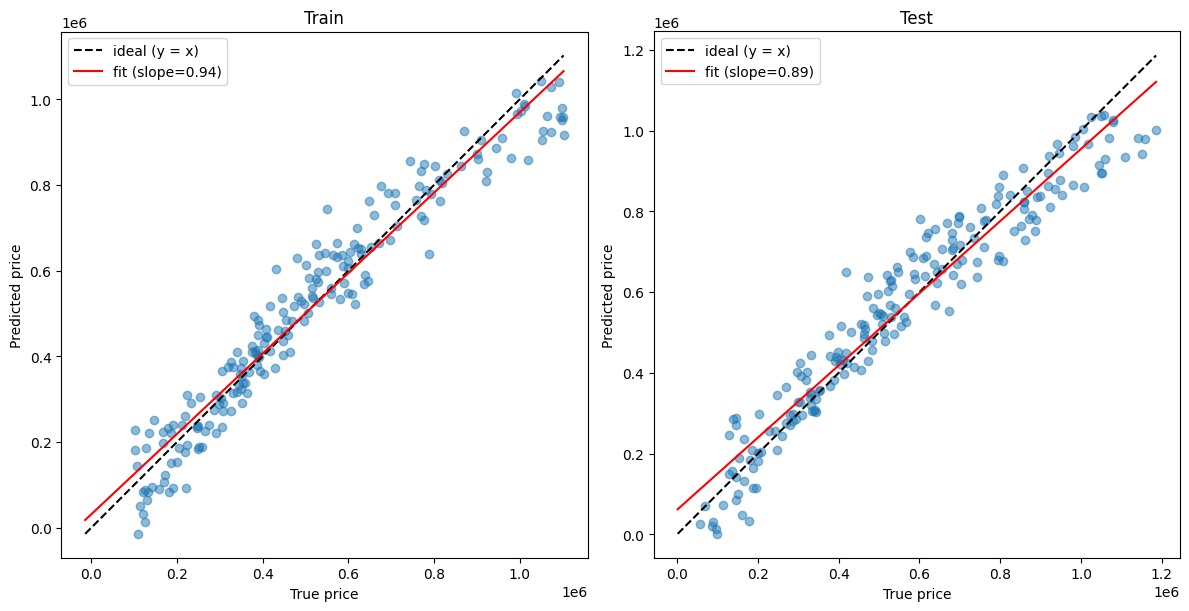

In [11]:
#

def pred_vs_true(ax, y, p, title):
    ax.scatter(y, p, alpha=0.5)
    lo, hi = min(y.min(), p.min()), max(y.max(), p.max())
    ax.plot([lo, hi], [lo, hi], "k--", label="ideal (y = x)")
    a, b = np.polyfit(y, p, 1)
    xs = np.array([lo, hi])
    ax.plot(xs, a * xs + b, "r-", label=f"fit (slope={a:.2f})")
    ax.set(xlabel="True price", ylabel="Predicted price", title=title)
    ax.set_aspect("equal"); ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
pred_vs_true(axes[0], y_train, train_predictions, "Train")
pred_vs_true(axes[1], y_test, test_predictions, "Test")
plt.tight_layout()


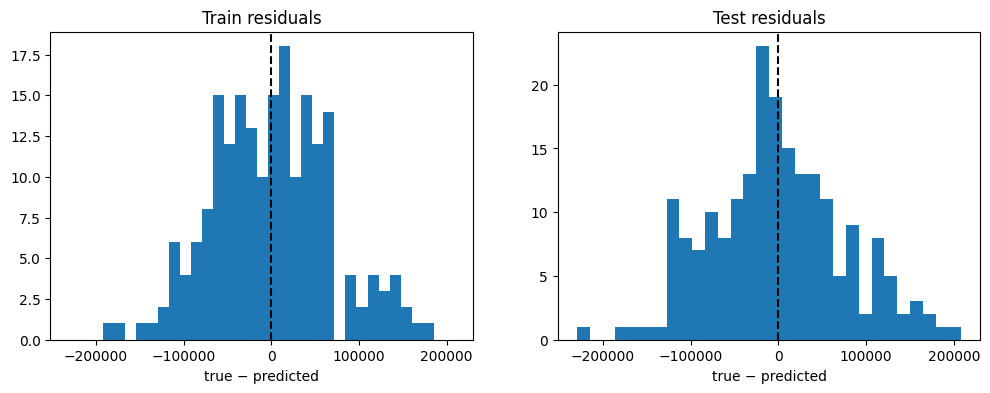

In [12]:
#

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, y, p, t in [(axes[0], y_train, train_predictions, "Train"),
                    (axes[1], y_test, test_predictions, "Test")]:
    ax.hist(y - p, bins=30); ax.axvline(0, color="k", ls="--")
    ax.set(title=f"{t} residuals", xlabel="true − predicted")

### Optional: generic solution

Use
```python
pipeline = Pipeline(steps=[
    ("encoder", ...),
    ...
    ("regressor", LinearRegression()),
])
```
to run all these steps with a simple `pipeline.fit(X_train, y_train)` and `pipeline.predict(X_test)`.

Use
```python
ColumnTransformer(
    transformers=[("prefix", step, list_of_columns)],
    remainder="passthrough",
)
```
to apply a step (like OneHotEncoder) to a subset of columns while leaving the rest unchanged. The resulting columns will be prefixed with the given string.
You can run `pipeline[i].get_feature_names_out()` to see the names of the features after each step.

Check out [PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html).

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

In [14]:
feature_cols_generic = [
    "area",
    "build_year",
    "district",  # We'll encode this as part of the pipeline now.
    "bedrooms",
    "bathrooms",
    "parking",
]

X_train, y_train = train_df_clean[feature_cols_generic], train_df_clean["price"]
X_test, y_test = test_df_clean[feature_cols_generic], test_df_clean["price"]

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(200, 6) (200,)
(205, 6) (205,)


In [15]:
### TODO ###

cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

encoder = ColumnTransformer(
                transformers=[
                    ("onehot", OneHotEncoder(handle_unknown="ignore", ), cat_cols),
                    ("scaler", StandardScaler(), num_cols),
                    ("poly", PolynomialFeatures(degree=2, include_bias=False), num_cols),
                            ],
                    remainder="passthrough",
                )

pipeline = Pipeline(steps=[
    ("encoder", encoder),
    ("regressor", LinearRegression()),
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

pipeline[0].get_feature_names_out()

array(['onehot__district_grodziskowo', 'onehot__district_mokotowo',
       'onehot__district_ochotowo', 'onehot__district_wolowo',
       'scaler__area', 'scaler__build_year', 'scaler__bedrooms',
       'scaler__bathrooms', 'scaler__parking', 'poly__area',
       'poly__build_year', 'poly__bedrooms', 'poly__bathrooms',
       'poly__parking', 'poly__area^2', 'poly__area build_year',
       'poly__area bedrooms', 'poly__area bathrooms',
       'poly__area parking', 'poly__build_year^2',
       'poly__build_year bedrooms', 'poly__build_year bathrooms',
       'poly__build_year parking', 'poly__bedrooms^2',
       'poly__bedrooms bathrooms', 'poly__bedrooms parking',
       'poly__bathrooms^2', 'poly__bathrooms parking', 'poly__parking^2'],
      dtype=object)

In [16]:
#

show_results(y_train, pipeline.predict(X_train), y_test, y_pred)

train: MAE=      50_202  RMSE=      61_190  R2=0.949
 test: MAE=      53_311  RMSE=      69_285  R2=0.942


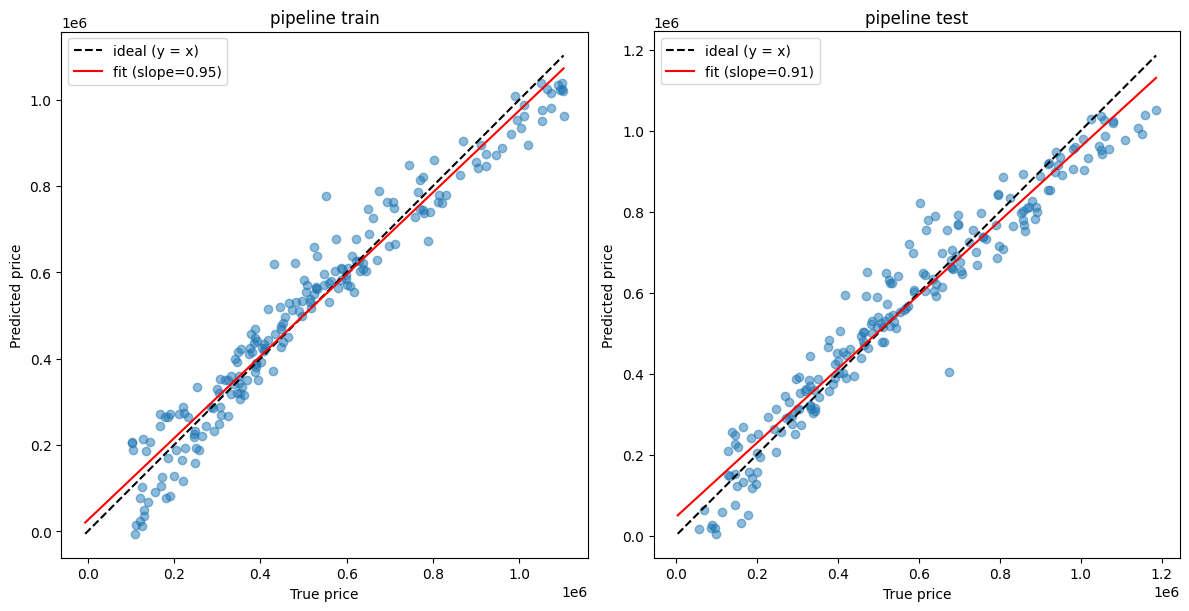

In [17]:
#

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
pred_vs_true(axes[0], y_train, pipeline.predict(X_train), "pipeline train")
pred_vs_true(axes[1], y_test, pipeline.predict(X_test), "pipeline test")
plt.tight_layout()


## Validation

In this exercise you will implement a validation pipeline: split the non-test set into train and validation sets and select the best model based on validation results.

So far you tested your model against the training and test datasets. As you should observe, there's a gap between the results. By validating your model, you should be able to better anticipate the test time performance and compare different models and hyperparameters on datasets they are not over-fitted to.

Implement the basic validation method, i.e. a random split.

In [18]:
def random_split(df: pd.DataFrame, val_ratio: float, seed: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Returns (train_df, val_df)."""
    ### TODO ###
    df_shuffled = df.sample(frac=1, random_state=seed)
    val_size = int(len(df_shuffled) * val_ratio)
    val_df = df_shuffled[:val_size]
    train_df = df_shuffled[val_size:]
    return train_df, val_df


new_train_df, val_df = random_split(train_df_clean, val_ratio=0.2, seed=42)

X_train, y_train = new_train_df[feature_cols], new_train_df["price"]
X_val, y_val = val_df[feature_cols], val_df["price"]
X_test, y_test = test_df_clean[feature_cols], test_df_clean["price"]

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(160, 6) (160,)
(40, 6) (40,)
(205, 6) (205,)


In [19]:
model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_val_pred = model.predict(X_val)
y_test_pred = model.predict(X_test)

show_results(y_train, y_train_pred, y_val, y_val_pred)

train: MAE=      96_007  RMSE=     113_611  R2=0.813
 test: MAE=     108_724  RMSE=     130_360  R2=0.809


In [20]:
#

from sklearn.base import clone

results = {}

def evaluate(name, model, X_tr, X_v, X_te):
    model.fit(X_tr, y_train)
    print(f"--- {name}")
    show_results(y_train, model.predict(X_tr), y_val, model.predict(X_v), val_name="val")
    results[name] = (np.sqrt(mean_squared_error(y_val, model.predict(X_v))), model, X_te)

# 1. Baseline
evaluate("baseline", LinearRegression(), X_train, X_val, X_test)

# 2. Hand-engineered, district averages recomputed from new_train_df only
avg_dist = new_train_df.groupby("district")["price"].mean()
global_mean = new_train_df["price"].mean()
add_avg = lambda X, df: X.assign(district_avg_price=df["district"].map(avg_dist).fillna(global_mean))
evaluate("hand", LinearRegression(),
         add_avg(X_train, new_train_df), add_avg(X_val, val_df), add_avg(X_test, test_df_clean))

# 3. Your pipeline with different polynomial degrees
X_train_gen, X_val_gen, X_test_gen = (d[feature_cols_generic] for d in (new_train_df, val_df, test_df_clean))
for degree in [1, 2, 3]:
    evaluate(f"pipeline_poly{degree}",
             clone(pipeline).set_params(encoder__poly__degree=degree),
             X_train_gen, X_val_gen, X_test_gen)

# 4. Variant: polynomial AFTER one-hot, so it can learn area x district interactions
for degree in [1, 2, 3]:
    interaction_pipeline = Pipeline(steps=[
        ("encoder", ColumnTransformer([
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
            ("scale", StandardScaler(), num_cols),
        ])),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("regressor", LinearRegression()),
    ])
    evaluate(f"interaction_poly{degree}", interaction_pipeline, X_train_gen, X_val_gen, X_test_gen)

best = min(results, key=lambda n: results[n][0])
print(f"\nBest on validation: {best}")

# Only now look at the test set, once, for the chosen model
_, best_model, X_te = results[best]
print(f"test: RMSE={np.sqrt(mean_squared_error(y_test, best_model.predict(X_te))):_.0f}  "
      f"R2={r2_score(y_test, best_model.predict(X_te)):.3f}")


--- baseline
train: MAE=      96_007  RMSE=     113_611  R2=0.813
  val: MAE=     108_724  RMSE=     130_360  R2=0.809
--- hand
train: MAE=      55_110  RMSE=      70_052  R2=0.929
  val: MAE=      60_820  RMSE=      78_695  R2=0.931
--- pipeline_poly1
train: MAE=      50_933  RMSE=      61_519  R2=0.945
  val: MAE=      52_375  RMSE=      66_179  R2=0.951
--- pipeline_poly2
train: MAE=      47_862  RMSE=      58_850  R2=0.950
  val: MAE=      55_839  RMSE=      76_427  R2=0.934
--- pipeline_poly3
train: MAE=      36_444  RMSE=      48_232  R2=0.966
  val: MAE=      59_538  RMSE=      88_473  R2=0.912
--- interaction_poly1
train: MAE=      50_933  RMSE=      61_519  R2=0.945
  val: MAE=      52_375  RMSE=      66_179  R2=0.951
--- interaction_poly2
train: MAE=      19_052  RMSE=      24_624  R2=0.991
  val: MAE=      26_600  RMSE=      34_348  R2=0.987
--- interaction_poly3
train: MAE=      13_008  RMSE=      17_276  R2=0.996
  val: MAE=      47_303  RMSE=      81_869  R2=0.925

Best o

## Cross-validation

To make the random split validation reliable, a significant chunk of training data may be needed. To get over this problem, one may apply cross-validation.

![alt-text](https://chrisjmccormick.files.wordpress.com/2013/07/10_fold_cv.png)

Implement a k-fold cross-validation method.

In [21]:


def kfold(df: pd.DataFrame, target, k: int = 5, shuffle: bool = True) -> list[float]:
    """Returns a list of validation losses for each of k folds."""
    if shuffle:
        df = df.sample(frac=1, random_state=42)
    fold_size = len(df) // k

    val_losses = []
    for i in range(k):
        print(f"Fold number {i} out of {k}")

        ### TODO ###
        # X_train, y_train = ...

        start = i * fold_size
        end = (i + 1) * fold_size if i < k - 1 else len(df)
        val_part = df.iloc[start:end]
        train_part = pd.concat([df.iloc[:start], df.iloc[end:]])

        X_train, y_train = train_part[feature_cols], train_part[target]
        X_val, y_val = val_part[feature_cols], val_part[target]

        model = LinearRegression()
        model.fit(X_train, y_train)
        y_val_pred = model.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
        print(f"    RMSE: {rmse:9_.0f}")
        val_losses.append(float(rmse))

    return val_losses


In [23]:
#

kfold_losses = kfold(train_df_clean, target="price", k=5, shuffle=True)

Fold number 0 out of 5
    RMSE:   130_360
Fold number 1 out of 5
    RMSE:   130_284
Fold number 2 out of 5
    RMSE:   124_419
Fold number 3 out of 5
    RMSE:   108_865
Fold number 4 out of 5
    RMSE:   105_365
